In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Base classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Ensemble classifiers
from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load Breast Cancer dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully!")
print("Dataset Shape:", X.shape)

print("\nFirst 5 records:")
display(X.head())

print("\nTarget Classes:")
print(data.target_names)


Dataset loaded successfully!
Dataset Shape: (569, 30)

First 5 records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target Classes:
['malignant' 'benign']


In [3]:

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (455, 30)
Testing data: (114, 30)


Base classifiers.
1. Logistic Regression
2. Decision Tree
3. Support Vector Machine (SVM)
4. K-Nearest Neighbors (KNN)
5. Naive Bayes

In [4]:

# Define base classifiers

base_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB()
}

print("Base classifiers created successfully!")


Base classifiers created successfully!


Train individual base classifiers

In [5]:

# Train individual classifiers

results = []

for name, model in base_models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

print("All base classifiers trained successfully!")


All base classifiers trained successfully!


Implement Stacking Ensemble
Base classifiers: Logistic Regression, Decision Tree and SVM.
Meta-classifier: Logistic Regression.

In [6]:

# Define base estimators for stacking

stacking_estimators = [
    ("lr", base_models["Logistic Regression"]),
    ("dt", base_models["Decision Tree"]),
    ("svm", base_models["SVM"])
]

# Create stacking classifier

stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5
)

# Train stacking model

stacking_model.fit(X_train, y_train)

# Make predictions

stacking_pred = stacking_model.predict(X_test)

# Evaluate

results.append({
    "Model": "Stacking Ensemble",
    "Accuracy": accuracy_score(y_test, stacking_pred),
    "Precision": precision_score(y_test, stacking_pred),
    "Recall": recall_score(y_test, stacking_pred),
    "F1 Score": f1_score(y_test, stacking_pred)
})

print("Stacking Ensemble implemented successfully!")
print("Stacking Accuracy:", accuracy_score(y_test, stacking_pred))


Stacking Ensemble implemented successfully!
Stacking Accuracy: 0.9736842105263158


Implement AdaBoost Ensemble

In [7]:

# Create AdaBoost classifier

ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train AdaBoost model

ada_model.fit(X_train, y_train)

# Make predictions

ada_pred = ada_model.predict(X_test)

# Evaluate

results.append({
    "Model": "AdaBoost Ensemble",
    "Accuracy": accuracy_score(y_test, ada_pred),
    "Precision": precision_score(y_test, ada_pred),
    "Recall": recall_score(y_test, ada_pred),
    "F1 Score": f1_score(y_test, ada_pred)
})

print("AdaBoost Ensemble implemented successfully!")
print("AdaBoost Accuracy:", accuracy_score(y_test, ada_pred))


AdaBoost Ensemble implemented successfully!
AdaBoost Accuracy: 0.956140350877193


Implement Voting Ensemble
Logistic Regression



Decision Tree



SVM

In [8]:

# Define voting classifiers

voting_estimators = [
    ("lr", base_models["Logistic Regression"]),
    ("dt", base_models["Decision Tree"]),
    ("svm", base_models["SVM"])
]

# Create voting classifier

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="hard"
)

# Train voting model

voting_model.fit(X_train, y_train)

# Make predictions

voting_pred = voting_model.predict(X_test)

# Evaluate

results.append({
    "Model": "Voting Ensemble",
    "Accuracy": accuracy_score(y_test, voting_pred),
    "Precision": precision_score(y_test, voting_pred),
    "Recall": recall_score(y_test, voting_pred),
    "F1 Score": f1_score(y_test, voting_pred)
})

print("Voting Ensemble implemented successfully!")
print("Voting Accuracy:", accuracy_score(y_test, voting_pred))


Voting Ensemble implemented successfully!
Voting Accuracy: 0.9824561403508771


Compare the performance of all models

In [9]:

# Create comparison dataframe

results_df = pd.DataFrame(results)

# Display performance comparison

print("PERFORMANCE COMPARISON OF ALL MODELS")

display(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    ).reset_index(drop=True).round(4)
)


PERFORMANCE COMPARISON OF ALL MODELS


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,SVM,0.9825,0.9861,0.9861,0.9861
2,Voting Ensemble,0.9825,0.9861,0.9861,0.9861
3,Stacking Ensemble,0.9737,0.9859,0.9722,0.9790
4,AdaBoost Ensemble,0.9561,0.9467,0.9861,0.9660
5,KNN,0.9561,0.9589,0.9722,0.9655
6,Naive Bayes,0.9386,0.9452,0.9583,0.9517
7,Decision Tree,0.9123,0.9559,0.9028,0.9286


Visualize model performance
Accuracy comparison graph

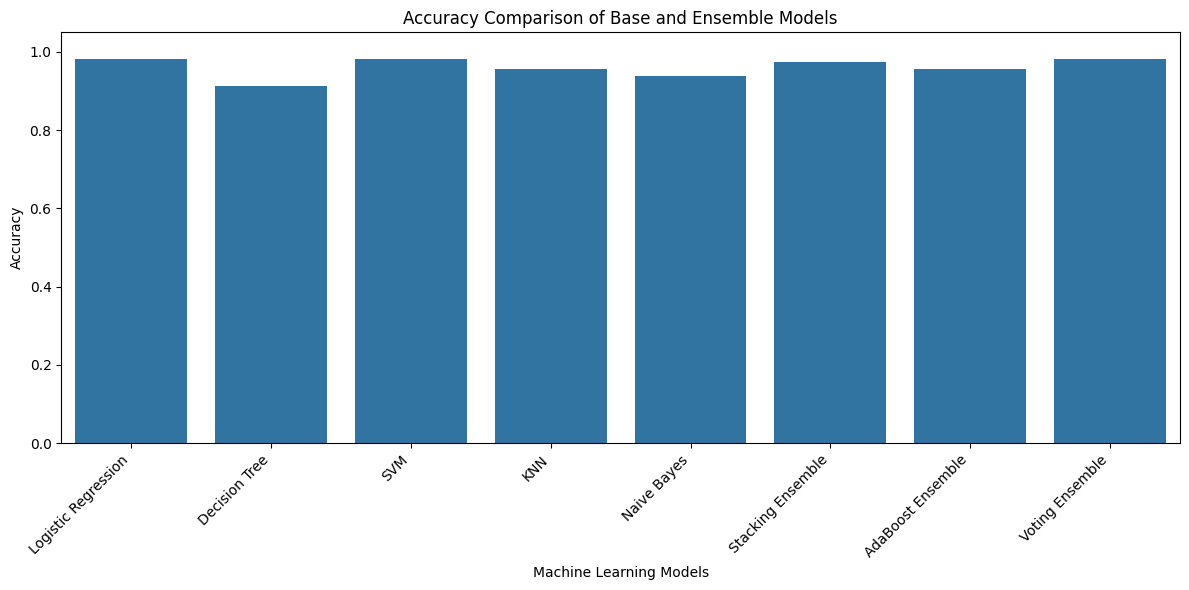

In [10]:

# Plot accuracy comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Base and Ensemble Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()


Confusion matrices

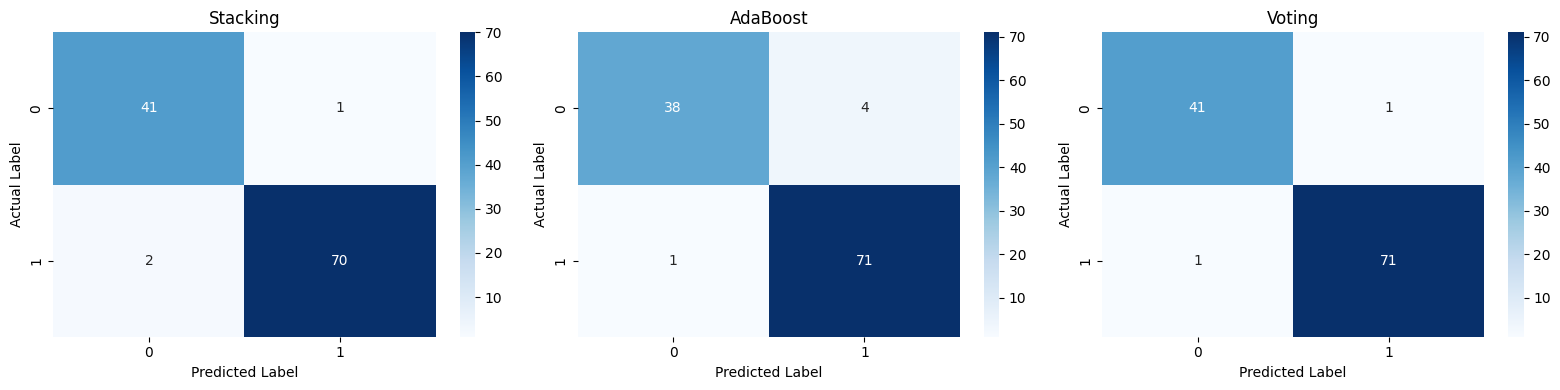

In [11]:

# Predictions from ensemble models

ensemble_predictions = {
    "Stacking": stacking_pred,
    "AdaBoost": ada_pred,
    "Voting": voting_pred
}

# Plot confusion matrices

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, predictions) in zip(
    axes, ensemble_predictions.items()
):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


Classification Report

In [12]:

# Display classification reports

for name, predictions in ensemble_predictions.items():

    print("\n", "=" * 45)
    print(name, "Classification Report")
    print("=" * 45)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=data.target_names
        )
    )



Stacking Classification Report
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


AdaBoost Classification Report
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Voting Classification Report
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98 